# Assignment 4: CIFAR-10 Energy-Based Model

Energy Based Methods: This notebook trains an energy model on RGB CIFAR-10 images and exports weights for FastAPI.

## 1. Imports and experiment settings

The convolutional network, Swish activation, Langevin sampling, replay buffer, contrastive divergence, and energy regularization are retained.
CIFAR-10 uses three channels and its native 32 x 32 resolution.

In [1]:
import copy
import json
import math
import random
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split
from torchvision.utils import make_grid, save_image
from tqdm.auto import tqdm

In [2]:
SEED = 42
BATCH_SIZE = 128
IMAGE_SIZE = 32
NUM_CHANNELS = 3
EPOCHS = 10
LEARNING_RATE = 0.0001
SAMPLE_STEPS = 60
RESUME_PATH = None

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))

import sys

PROJECT_DIR = None
for folder in (Path.cwd(), *Path.cwd().parents):
    for candidate in (folder, folder / "APAN_5560genai_ass1"):
        if (candidate / "app" / "main.py").is_file():
            PROJECT_DIR = candidate.resolve()
            break
    if PROJECT_DIR is not None:
        break
if PROJECT_DIR is None:
    raise FileNotFoundError("Cannot find the APAN_5560genai_ass1 project near this notebook.")
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

DATA_DIR = PROJECT_DIR / "data"
MODEL_DIR = PROJECT_DIR / "models"
if RESUME_PATH is None:
    RUN_DIR = PROJECT_DIR.parent / "ASS4" / "outputs"/ ("energy_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
else:
    RESUME_PATH = Path(RESUME_PATH)
    RUN_DIR = RESUME_PATH.parent.parent
CHECKPOINT_DIR = RUN_DIR / "checkpoints"
SAMPLE_DIR = RUN_DIR / "samples"
for directory in (MODEL_DIR, CHECKPOINT_DIR, SAMPLE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
print("Device:", device)
print("Run directory:", RUN_DIR)

Device: cuda
Run directory: C:\Users\Milan_Chen\Desktop\SEM3\genai 5560\ASS4\outputs\energy_20261118_133522_361167


## 2. Load CIFAR-10

Pixels are mapped from [0, 1] to [-1, 1]. The original training split is divided into 45,000 training and 5,000 validation images.
The 10,000 test images are kept for the final diagnostic. Class labels are not used for training.
Windows notebook loaders use zero worker processes.

In [3]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])
full_train_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR, train=True, download=True, transform=transform
)
train_dataset, val_dataset = random_split(
    full_train_dataset, [45000, 5000],
    generator=torch.Generator().manual_seed(SEED)
)
test_dataset = torchvision.datasets.CIFAR10(
    root=DATA_DIR, train=False, download=True, transform=transform
)
train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=0,
    generator=torch.Generator().manual_seed(SEED)
)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
print("Train:", len(train_dataset), "Validation:", len(val_dataset), "Test:", len(test_dataset))

Train: 45000 Validation: 5000 Test: 10000


Image batch: torch.Size([128, 3, 32, 32])


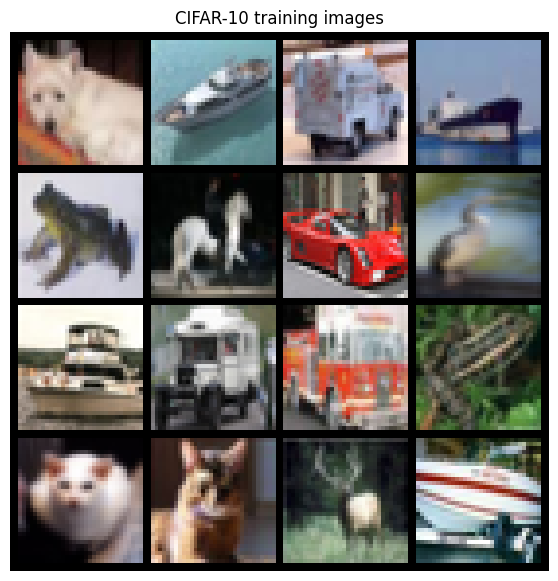

In [4]:
def show_images(images, title, nrow=4):
    grid = make_grid(images.detach().cpu(), nrow=nrow)
    plt.figure(figsize=(7, 7))
    plt.imshow(grid.permute(1, 2, 0))
    plt.title(title)
    plt.axis("off")
    plt.show()

images, labels = next(iter(train_loader))
print("Image batch:", images.shape)
show_images(((images[:16] + 1) / 2).clamp(0, 1), "CIFAR-10 training images")

## 3. Define the energy network

Four stride-2 convolutions reduce 32 x 32 images to 2 x 2 feature maps.
The output is one scalar energy per image. 

In [5]:
def swish(x):
    return x * torch.sigmoid(x)


class EnergyModel(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=5, stride=2, padding=2)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, stride=2, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, stride=2, padding=1)
        self.conv4 = nn.Conv2d(64, 64, kernel_size=3, stride=2, padding=1)
        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(64 * 2 * 2, 64)
        self.fc2 = nn.Linear(64, 1)

    def forward(self, x):
        x = swish(self.conv1(x))
        x = swish(self.conv2(x))
        x = swish(self.conv3(x))
        x = swish(self.conv4(x))
        x = self.flatten(x)
        x = swish(self.fc1(x))
        return self.fc2(x)

## 4. Sample images with Langevin dynamics

Add noise, calculate the energy gradient with respect to the image, and move against that gradient. Sampling updates pixels, not network weights. Gradient tracking is enabled only for the energy calculation, and the previous model mode is restored afterward.

In [6]:
def generate_samples(nn_energy_model, inp_imgs, steps, step_size, noise_std):
    if steps < 1:
        raise ValueError("steps must be positive.")
    was_training = nn_energy_model.training
    nn_energy_model.eval()
    inp_imgs = inp_imgs.detach()
    try:
        for _ in range(steps):
            with torch.no_grad():
                noise = torch.randn_like(inp_imgs) * noise_std
                inp_imgs = (inp_imgs + noise).clamp(-1.0, 1.0)
            with torch.enable_grad():
                inp_imgs.requires_grad_(True)
                energy = nn_energy_model(inp_imgs)
                grads, = torch.autograd.grad(
                    energy, inp_imgs, grad_outputs=torch.ones_like(energy)
                )
            with torch.no_grad():
                grads = grads.clamp(-0.03, 0.03)
                inp_imgs = (inp_imgs - step_size * grads).clamp(-1.0, 1.0)
    finally:
        nn_energy_model.train(was_training)
    return inp_imgs.detach()

## 5. Reuse generated samples

The replay buffer retains up to 8,192 images. Around 5% of each batch starts from new noise. The batch size is taken from the current real batch so the final partial batch also works. An all-new batch is handled explicitly.

In [7]:
class Buffer:
    def __init__(self, model, device):
        self.model = model
        self.device = device
        self.examples = [
            torch.rand((1, 3, 32, 32), device=device) * 2 - 1
            for _ in range(128)
        ]

    def sample_new_exmps(self, batch_size, steps, step_size, noise):
        n_new = np.random.binomial(batch_size, 0.05)
        new_rand_imgs = torch.rand((n_new, 3, 32, 32), device=self.device) * 2 - 1
        old_examples = random.choices(self.examples, k=batch_size - n_new)
        if old_examples:
            old_imgs = torch.cat(old_examples, dim=0)
            inp_imgs = torch.cat([new_rand_imgs, old_imgs], dim=0)
        else:
            inp_imgs = new_rand_imgs
        new_imgs = generate_samples(self.model, inp_imgs, steps, step_size, noise)
        self.examples = [img.clone() for img in new_imgs.split(1)] + self.examples
        self.examples = self.examples[:8192]
        return new_imgs

## 6. Train the energy function

Minimize mean real energy minus mean generated energy, plus the squared-energy regularizer. Gradients update network parameters during training. Metrics are weighted by batch size. The validation diagnostic compares real images against uniform random images; it is not an image-quality or classification metric.

In [8]:
class Metric:
    def __init__(self):
        self.reset()

    def update(self, val, count=1):
        self.total += val.item() * count
        self.count += count

    def result(self):
        return self.total / self.count if self.count > 0 else 0.0

    def reset(self):
        self.total = 0.0
        self.count = 0


class EBM(nn.Module):
    def __init__(self, model, alpha, steps, step_size, noise, device):
        super().__init__()
        self.device = device
        self.model = model.to(device)
        self.buffer = Buffer(self.model, device)
        self.alpha = alpha
        self.steps = steps
        self.step_size = step_size
        self.noise = noise
        self.loss_metric = Metric()
        self.reg_loss_metric = Metric()
        self.cdiv_loss_metric = Metric()
        self.real_out_metric = Metric()
        self.fake_out_metric = Metric()

    def metrics(self):
        return {
            "loss": self.loss_metric.result(),
            "reg": self.reg_loss_metric.result(),
            "cdiv": self.cdiv_loss_metric.result(),
            "real": self.real_out_metric.result(),
            "fake": self.fake_out_metric.result(),
        }

    def reset_metrics(self):
        for metric in (self.loss_metric, self.reg_loss_metric, self.cdiv_loss_metric,
                       self.real_out_metric, self.fake_out_metric):
            metric.reset()

    def train_step(self, real_imgs, optimizer):
        self.model.train()
        real_imgs = real_imgs.to(self.device)
        real_imgs = (real_imgs + torch.randn_like(real_imgs) * self.noise).clamp(-1, 1)
        batch_size = real_imgs.size(0)
        fake_imgs = self.buffer.sample_new_exmps(
            batch_size, self.steps, self.step_size, self.noise
        )
        inp_imgs = torch.cat([real_imgs, fake_imgs], dim=0).detach()
        out_scores = self.model(inp_imgs)
        real_out, fake_out = torch.split(out_scores, [batch_size, batch_size], dim=0)
        cdiv_loss = real_out.mean() - fake_out.mean()
        reg_loss = self.alpha * (real_out.square().mean() + fake_out.square().mean())
        loss = cdiv_loss + reg_loss
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(self.model.parameters(), max_norm=0.1)
        optimizer.step()
        self.loss_metric.update(loss, batch_size)
        self.reg_loss_metric.update(reg_loss, batch_size)
        self.cdiv_loss_metric.update(cdiv_loss, batch_size)
        self.real_out_metric.update(real_out.mean(), batch_size)
        self.fake_out_metric.update(fake_out.mean(), batch_size)
        return self.metrics()

    def test_step(self, real_imgs):
        self.model.eval()
        real_imgs = real_imgs.to(self.device)
        batch_size = real_imgs.size(0)
        fake_imgs = torch.rand_like(real_imgs) * 2 - 1
        with torch.no_grad():
            out_scores = self.model(torch.cat([real_imgs, fake_imgs], dim=0))
            real_out, fake_out = out_scores.split(batch_size)
            cdiv = real_out.mean() - fake_out.mean()
        self.cdiv_loss_metric.update(cdiv, batch_size)
        self.real_out_metric.update(real_out.mean(), batch_size)
        self.fake_out_metric.update(fake_out.mean(), batch_size)
        return {
            "cdiv": self.cdiv_loss_metric.result(),
            "real": self.real_out_metric.result(),
            "fake": self.fake_out_metric.result(),
        }

## 7. Create or resume an experiment

The learning rate, regularization coefficient, and sampling settings below are explicit starting choices.
To resume, set RESUME_PATH in the settings cell to an energy_latest.pth file.
The optimizer, replay buffer, sampling settings, and history are restored.
EPOCHS is the total target epoch count. Resuming is not guaranteed to reproduce an uninterrupted run because all random-number states are not saved.

In [9]:
energy_model = EnergyModel().to(device)
ebm = EBM(energy_model, alpha=0.1, steps=60, step_size=10.0, noise=0.005, device=device)
optimizer = optim.Adam(energy_model.parameters(), lr=LEARNING_RATE)
fixed_noise = torch.rand(16, 3, 32, 32, device=device) * 2 - 1
start_epoch = 0
history = []

if RESUME_PATH is not None:
    checkpoint = torch.load(RESUME_PATH, map_location=device, weights_only=True)
    energy_model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])
    ebm.buffer.examples = list(checkpoint["buffer_examples"].to(device).split(1))
    for name in ("alpha", "steps", "step_size", "noise"):
        setattr(ebm, name, checkpoint[name])
    fixed_noise = checkpoint["fixed_noise"].to(device)
    start_epoch = checkpoint["epoch"]
    history = checkpoint["history"]

print("Energy output shape:", energy_model(images[:2].to(device)).shape)
print("Completed epochs:", start_epoch)

Energy output shape: torch.Size([2, 1])
Completed epochs: 0


## 8. Train and save progress

Each epoch saves a generated grid, history.json, and energy_latest.pth.
The checkpoint includes the replay buffer and optimizer for continuation.
The same initial images are reused for epoch grids, but Langevin noise is resampled.
Review sample grids as well as losses before deciding whether more training is needed.

In [10]:
def train_energy(ebm, train_loader, val_loader, optimizer, epochs,
                 checkpoint_dir, sample_dir, fixed_noise, sample_steps,
                 start_epoch=0, history=None):
    history = [] if history is None else history
    for epoch in range(start_epoch, epochs):
        ebm.reset_metrics()
        progress = tqdm(train_loader, desc=f"Epoch {epoch + 1}/{epochs} [Train]")
        for images, _ in progress:
            metrics = ebm.train_step(images.to(ebm.device), optimizer)
            progress.set_postfix(loss=f"{metrics['loss']:.4f}")
        train_metrics = ebm.metrics().copy()
        ebm.reset_metrics()
        for images, _ in tqdm(val_loader, desc="Validation"):
            ebm.test_step(images.to(ebm.device))
        val_metrics = ebm.metrics().copy()
        record = {
            "epoch": epoch + 1,
            "train_loss": train_metrics["loss"],
            "train_real_energy": train_metrics["real"],
            "train_fake_energy": train_metrics["fake"],
            "val_real_energy": val_metrics["real"],
            "val_random_energy": val_metrics["fake"],
            "val_energy_gap": val_metrics["cdiv"],
        }
        history.append(record)
        samples = generate_samples(
            ebm.model, fixed_noise.clone(), sample_steps, ebm.step_size, ebm.noise
        )
        samples = ((samples + 1) / 2).clamp(0, 1)
        save_image(samples, sample_dir / f"epoch_{epoch + 1:03d}.png", nrow=4)
        checkpoint = {
            "epoch": epoch + 1,
            "model_state_dict": ebm.model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "buffer_examples": torch.cat(ebm.buffer.examples).cpu(),
            "fixed_noise": fixed_noise.cpu(),
            "history": history,
            "alpha": ebm.alpha,
            "steps": ebm.steps,
            "step_size": ebm.step_size,
            "noise": ebm.noise,
            "image_size": 32,
            "num_channels": 3,
        }
        torch.save(checkpoint, checkpoint_dir / "energy_latest.pth")
        (checkpoint_dir.parent / "history.json").write_text(json.dumps(history, indent=2))
        print(record)
        show_images(samples, f"Energy model: epoch {epoch + 1}")
    return history

Epoch 1/10 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

C:\Users\Milan_Chen\Documents\ChatGPT\anomaly detection\.venv-ass5-gpu\Lib\site-packages\torch\autograd\graph.py:979: UserWarning: Attempting to run cuBLAS, but there was no current CUDA context! Attempting to set the primary context... (Triggered internally at C:\actions-runner\_work\pytorch\pytorch\aten\src\ATen\cuda\CublasHandlePool.cpp:408.)
  return Variable._execution_engine.run_backward(  # Calls into the C++ engine to run the backward pass


Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': -0.0026651271938449806, 'train_real_energy': -0.005739534217450354, 'train_fake_energy': -0.0008849663449658287, 'val_real_energy': 0.020365798765420915, 'val_random_energy': 0.10440698564052582, 'val_energy_gap': -0.08404118673205375}


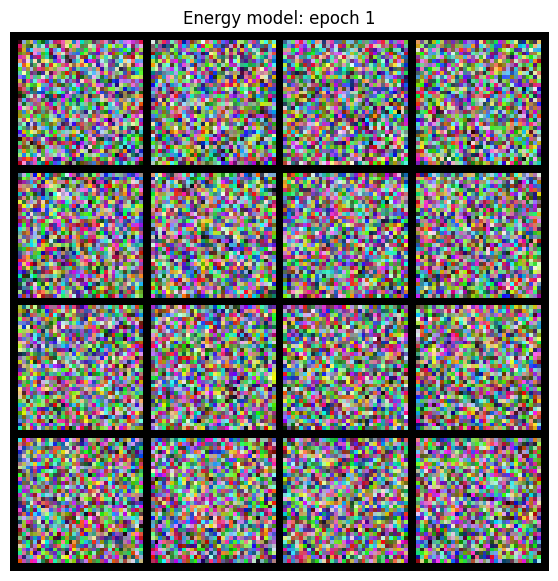

Epoch 2/10 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 2, 'train_loss': -0.00019725018512043688, 'train_real_energy': 0.002189272761883007, 'train_fake_energy': 0.0026748752574953768, 'val_real_energy': 2.6837052404880525e-05, 'val_random_energy': 0.22675959730148315, 'val_energy_gap': -0.22673275949954985}


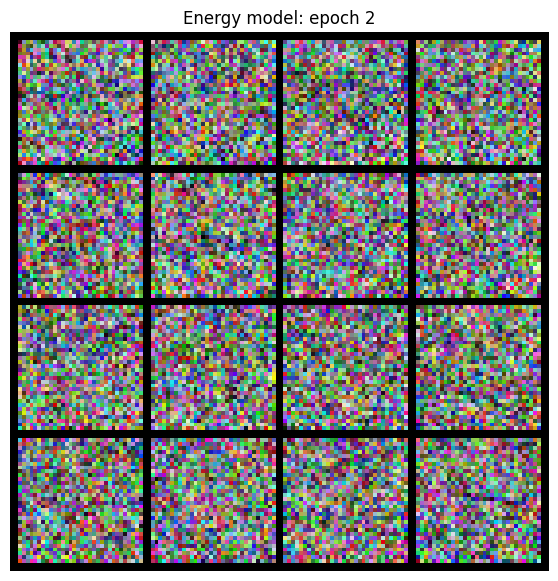

Epoch 3/10 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 3, 'train_loss': 0.00019249867904517386, 'train_real_energy': -0.0014185528161625067, 'train_fake_energy': -0.0012616349172261026, 'val_real_energy': -0.013146480859816075, 'val_random_energy': 0.43588515844345094, 'val_energy_gap': -0.4490316368103027}


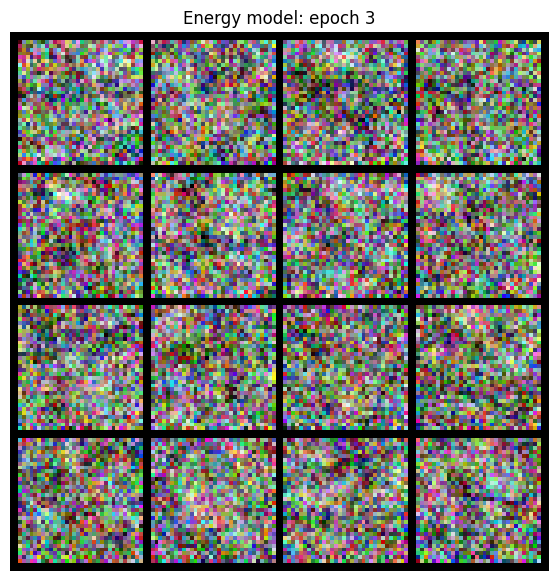

Epoch 4/10 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 4, 'train_loss': 0.0006046274508660039, 'train_real_energy': 0.0008986659853822655, 'train_fake_energy': 0.00047442712200184664, 'val_real_energy': -0.010088443149626255, 'val_random_energy': 0.6899353202819825, 'val_energy_gap': -0.7000237648010253}


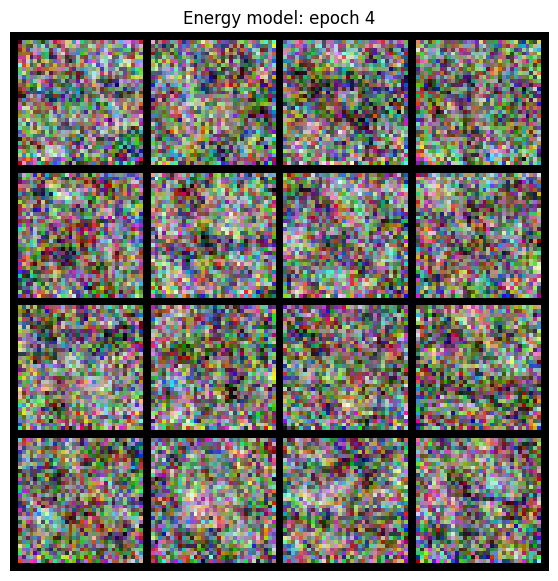

Epoch 5/10 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 5, 'train_loss': -0.0001564300946891308, 'train_real_energy': 0.0014546236633426613, 'train_fake_energy': 0.0017396171691517034, 'val_real_energy': 0.006099283772706986, 'val_random_energy': 1.0907217948913575, 'val_energy_gap': -1.0846225151062012}


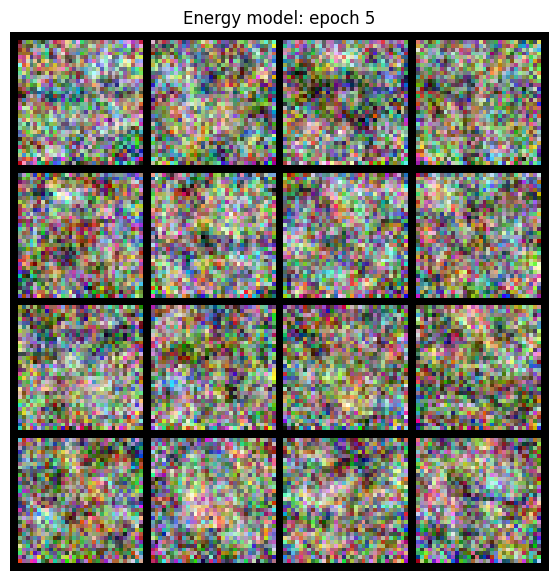

Epoch 6/10 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 6, 'train_loss': 3.1463142587906783e-06, 'train_real_energy': 0.00022138021397921775, 'train_fake_energy': 0.00031732275734345117, 'val_real_energy': 0.0025950435020029544, 'val_random_energy': 1.5224037021636962, 'val_energy_gap': -1.5198086614608766}


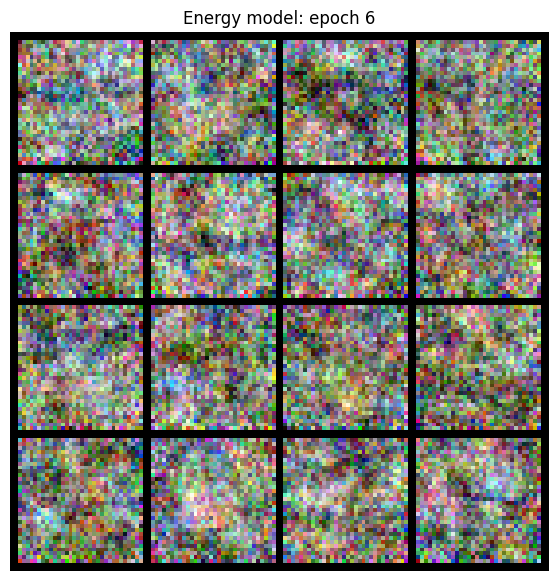

Epoch 7/10 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 7, 'train_loss': -0.00020582364217067758, 'train_real_energy': 0.0006940789375868108, 'train_fake_energy': 0.00098132156735907, 'val_real_energy': 2.093944847583771e-05, 'val_random_energy': 1.9574052879333497, 'val_energy_gap': -1.9573843427658082}


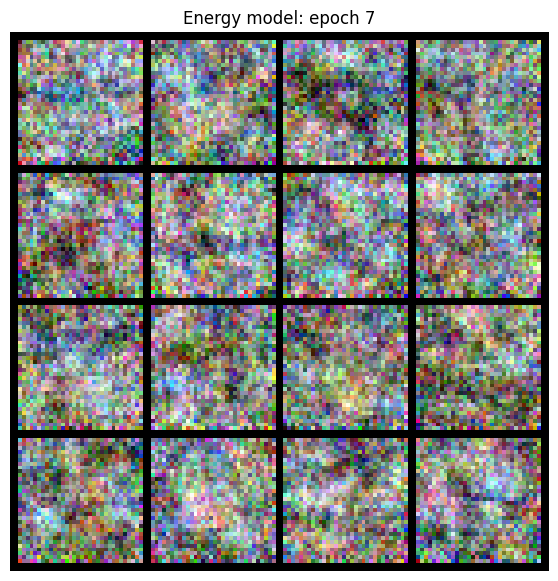

Epoch 8/10 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 8, 'train_loss': 6.933928418697583e-05, 'train_real_energy': -0.00010527062639594079, 'train_fake_energy': -8.728845156729221e-05, 'val_real_energy': -0.001763200418651104, 'val_random_energy': 2.3758506462097166, 'val_energy_gap': -2.3776138355255125}


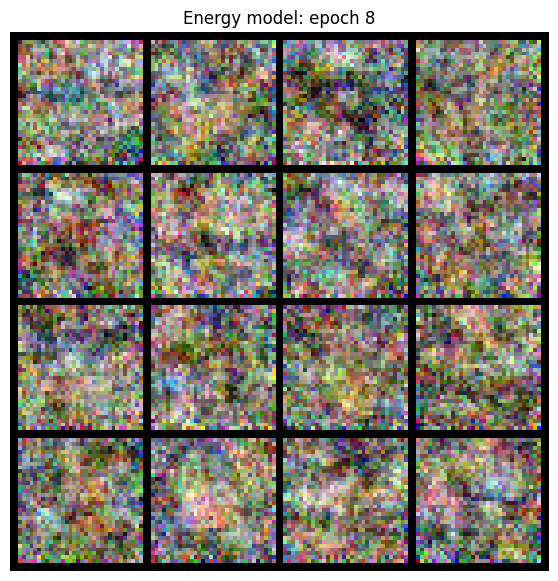

Epoch 9/10 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 9, 'train_loss': -1.701138788420293e-05, 'train_real_energy': 0.00024643938802182674, 'train_fake_energy': 0.0003223435441652934, 'val_real_energy': -0.00016322878003120422, 'val_random_energy': 2.935490118408203, 'val_energy_gap': -2.935653349685669}


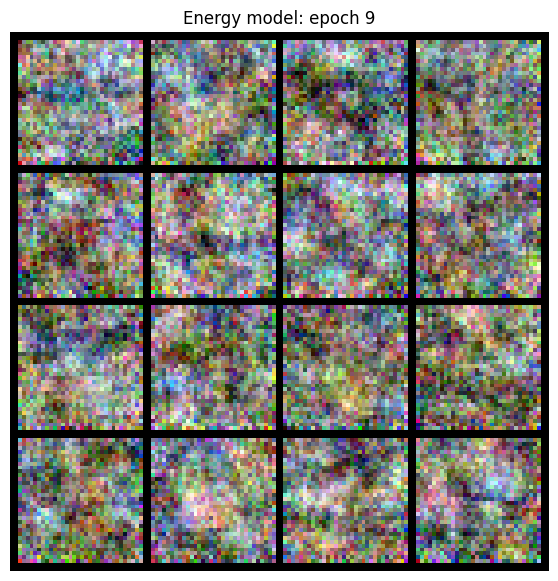

Epoch 10/10 [Train]:   0%|          | 0/352 [00:00<?, ?it/s]

Validation:   0%|          | 0/40 [00:00<?, ?it/s]

{'epoch': 10, 'train_loss': -0.00010872409718124093, 'train_real_energy': 0.000356965604569349, 'train_fake_energy': 0.000525625561674436, 'val_real_energy': -0.003369656777754426, 'val_random_energy': 3.358756219100952, 'val_energy_gap': -3.362125862503052}


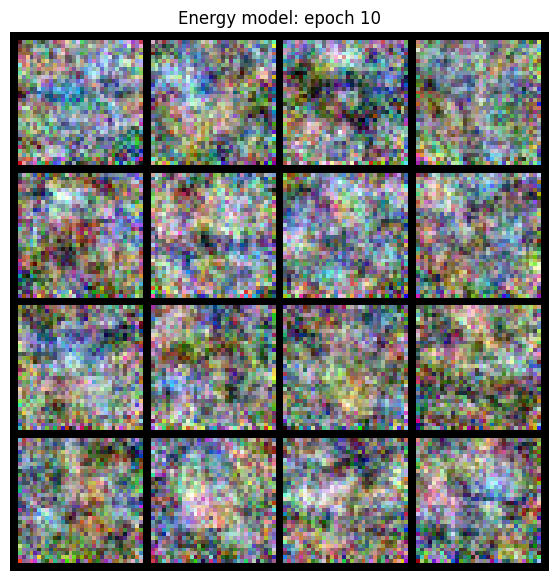

In [11]:
history = train_energy(
    ebm, train_loader, val_loader, optimizer, EPOCHS,
    CHECKPOINT_DIR, SAMPLE_DIR, fixed_noise, SAMPLE_STEPS,
    start_epoch=start_epoch, history=history
)

## 9. Inspect training and the held-out diagnostic

An energy gap describes the model's scores for the chosen image distributions.
It does not establish sample realism. Compare the saved images with real CIFAR-10 images.

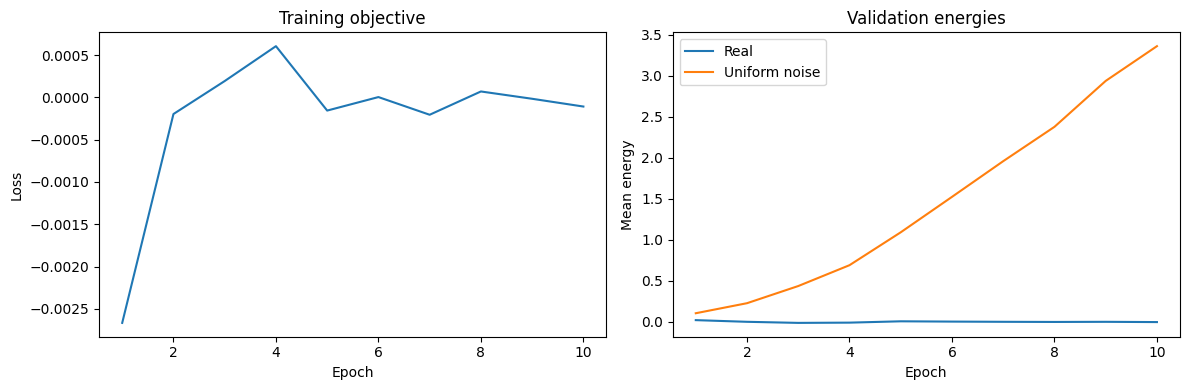

Test diagnostic:   0%|          | 0/79 [00:00<?, ?it/s]

{'cdiv': -3.3607475353240965, 'real': -0.0031276770869269966, 'fake': 3.357619863128662}


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
epochs = [row["epoch"] for row in history]
axes[0].plot(epochs, [row["train_loss"] for row in history])
axes[0].set(title="Training objective", xlabel="Epoch", ylabel="Loss")
axes[1].plot(epochs, [row["val_real_energy"] for row in history], label="Real")
axes[1].plot(epochs, [row["val_random_energy"] for row in history], label="Uniform noise")
axes[1].set(title="Validation energies", xlabel="Epoch", ylabel="Mean energy")
axes[1].legend()
plt.tight_layout()
plt.show()

ebm.reset_metrics()
for images, _ in tqdm(test_loader, desc="Test diagnostic"):
    test_metrics = ebm.test_step(images.to(device))
print(test_metrics)

After 10 epochs, the model assigns lower energy to real CIFAR-10 images than to uniform random noise. However, the generated samples remain dominated by colored textures and grid-like patterns, without clearly recognizable objects. The energy gap therefore does not demonstrate realistic image generation.

## 10. Compare sampling steps

Use the trained energy model to compare 60, 200, and 500 Langevin steps.
All settings share the same initial images and random seed, so the shorter sampling runs follow the same initial trajectory as the longer runs. Model weights remain unchanged.
Compare object structure, noise, and repeated patterns. Lower energy alone does not establish better image quality.

Steps: 60, mean energy: 0.049897
Steps: 200, mean energy: 0.007644
Steps: 500, mean energy: -0.014984


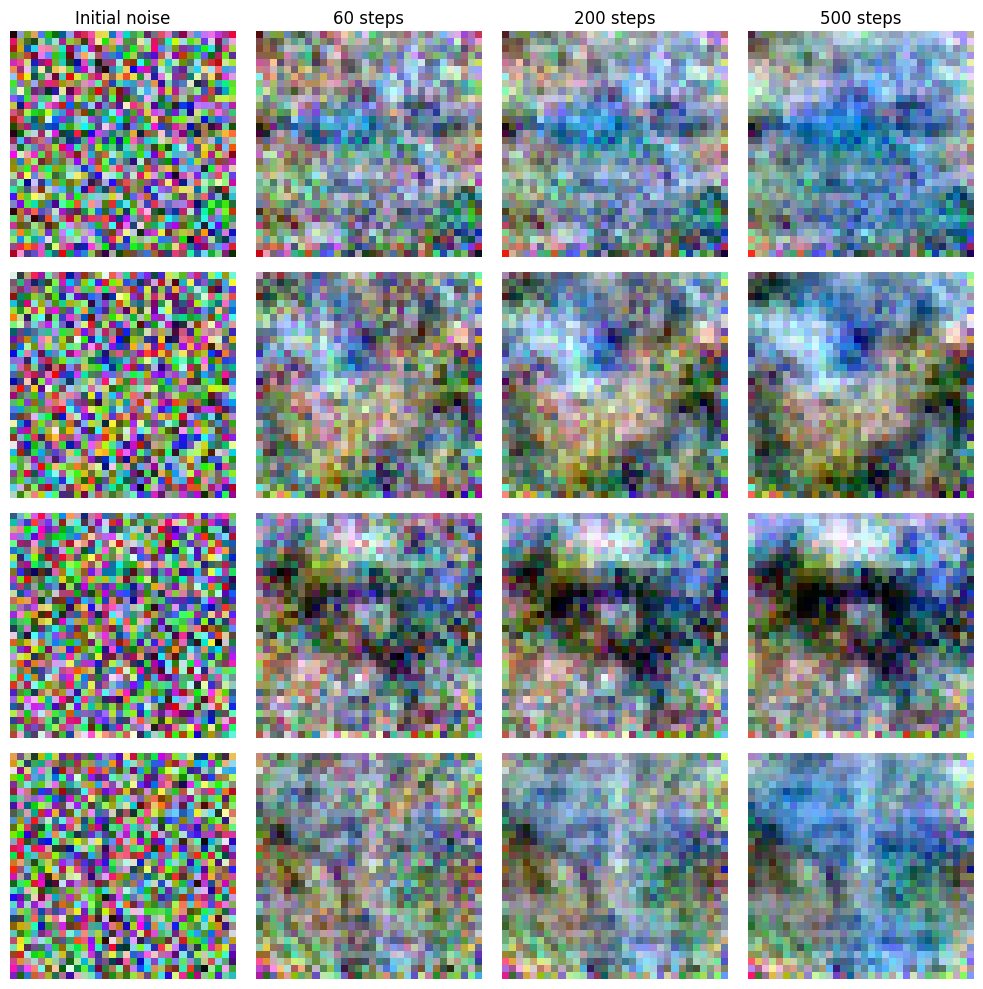

Saved: C:\Users\Milan_Chen\Desktop\SEM3\genai 5560\ASS4\outputs\energy_20261118_133522_361167\samples\sampling_steps_comparison.png


In [14]:
energy_model.eval()

initial_images = fixed_noise[:4].detach().clone().to(device)
step_counts = [60, 200, 500]
results = {}
cuda_devices = [torch.cuda.current_device()] if device.type == "cuda" else []

for steps in step_counts:
    with torch.random.fork_rng(devices=cuda_devices):
        torch.manual_seed(123)
        samples = generate_samples(
            energy_model,
            initial_images.clone(),
            steps=steps,
            step_size=ebm.step_size,
            noise_std=ebm.noise,
        )

    results[steps] = samples.detach().cpu()

    with torch.no_grad():
        mean_energy = energy_model(samples).mean().item()

    print(f"Steps: {steps}, mean energy: {mean_energy:.6f}")

columns = [initial_images.cpu()] + [results[s] for s in step_counts]
titles = ["Initial noise"] + [f"{s} steps" for s in step_counts]

fig, axes = plt.subplots(4, 4, figsize=(10, 10))

for col, (batch, title) in enumerate(zip(columns, titles)):
    display_images = ((batch + 1) / 2).clamp(0, 1)

    for row in range(4):
        axes[row, col].imshow(display_images[row].permute(1, 2, 0))
        axes[row, col].axis("off")

        if row == 0:
            axes[row, col].set_title(title)

plt.tight_layout()
comparison_path = SAMPLE_DIR / "sampling_steps_comparison.png"
plt.savefig(comparison_path, dpi=150, bbox_inches="tight")
plt.show()

print("Saved:", comparison_path)

## 11. Export and verify the API checkpoint

Export the final trained network to models/cifar10_energy.pth. The API uses
the matching EnergyModel and generate_samples definitions in helper_lib/energy.py.
Reload on CPU and compare its energy scores with the GPU-trained model before generating fresh samples.
This cell replaces an existing export at the same path. Restart the API after re-exporting.

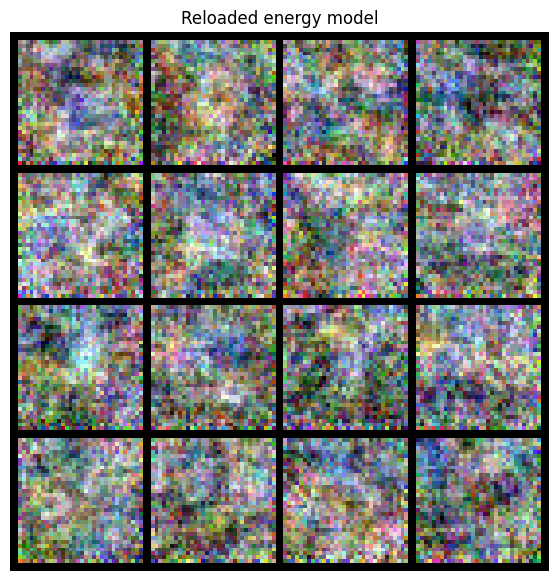

Exported: C:\Users\Milan_Chen\Desktop\SEM3\genai 5560\APAN_5560genai_ass1\models\cifar10_energy.pth


In [13]:
checkpoint = torch.load(CHECKPOINT_DIR / "energy_latest.pth", map_location="cpu", weights_only=True)
export = {name: checkpoint[name] for name in (
    "model_state_dict", "epoch", "image_size", "num_channels", "step_size", "noise"
)}
export_path = MODEL_DIR / "cifar10_energy.pth"
torch.save(export, export_path)

from helper_lib.energy import EnergyModel as APIEnergyModel
from helper_lib.energy import generate_samples as api_generate_samples

reloaded_model = APIEnergyModel()
reloaded_model.load_state_dict(torch.load(export_path, weights_only=True)["model_state_dict"])
reloaded_model.eval()
energy_model.eval()
probe = fixed_noise[:2]
with torch.no_grad():
    expected = energy_model(probe).cpu()
    actual = reloaded_model(probe.cpu())
torch.testing.assert_close(actual, expected, rtol=1e-4, atol=1e-5)
samples = api_generate_samples(
    reloaded_model, torch.rand(16, 3, 32, 32) * 2 - 1,
    SAMPLE_STEPS, export["step_size"], export["noise"]
)
samples = ((samples + 1) / 2).clamp(0, 1)
save_image(samples, SAMPLE_DIR / "final_samples.png", nrow=4)
show_images(samples, "Reloaded energy model")
print("Exported:", export_path)

## 12. Use the FastAPI endpoint

From the repository root, start the existing application with
`uv run fastapi dev app/main.py`. Open
`http://127.0.0.1:8000/generate-energy?num_samples=4&steps=60`.
The response is a PNG grid. Missing weights return HTTP 503; invalid query values return HTTP 422.
See ASSIGNMENT4.md for Docker and GitHub submission steps.